In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, average_precision_score)

import os
DATA_FILE = "creditcard.csv" if os.path.exists("creditcard.csv") else "creditcard.csv.zip"
df = pd.read_csv(DATA_FILE)
print("Rows and columns:", df.shape)
print("Duplicate rows:", df.duplicated().sum())
print("Missing values:", df.isnull().sum().sum())
print()
print("Share of each class (%):")
print((df["Class"].value_counts(normalize=True) * 100).round(3))

Rows and columns: (284807, 31)
Duplicate rows: 1081
Missing values: 0

Share of each class (%):
Class
0    99.827
1     0.173
Name: proportion, dtype: float64


In [2]:
df["hour"] = (df["Time"] // 3600) % 24
print("Fraud rate (%) by hour of day:")
print((df.groupby("hour")["Class"].mean() * 100).round(3))

df["amount_band"] = pd.cut(df["Amount"], [-1, 10, 50, 200, 1000, 1e6],
                           labels=["0-10", "10-50", "50-200", "200-1000", "1000+"])
print()
print("Transactions, frauds and fraud rate by amount band:")
print(df.groupby("amount_band", observed=True)["Class"].agg(["count", "sum", "mean"]))

print()
print("Amount: normal (0) vs fraud (1):")
print(df.groupby("Class")["Amount"].describe().round(2))

Fraud rate (%) by hour of day:
hour
0.0     0.078
1.0     0.237
2.0     1.713
3.0     0.487
4.0     1.041
5.0     0.368
6.0     0.219
7.0     0.318
8.0     0.088
9.0     0.101
10.0    0.048
11.0    0.314
12.0    0.110
13.0    0.111
14.0    0.139
15.0    0.158
16.0    0.134
17.0    0.179
18.0    0.194
19.0    0.121
20.0    0.107
21.0    0.090
22.0    0.058
23.0    0.192
Name: Class, dtype: float64

Transactions, frauds and fraud rate by amount band:
              count  sum      mean
amount_band                       
0-10         100264  249  0.002483
10-50         90781   57  0.000628
50-200        64925  101  0.001556
200-1000      25897   76  0.002935
1000+          2940    9  0.003061

Amount: normal (0) vs fraud (1):
          count    mean     std  min   25%    50%     75%       max
Class                                                              
0      284315.0   88.29  250.11  0.0  5.65  22.00   77.05  25691.16
1         492.0  122.21  256.68  0.0  1.00   9.25  105.89   2125

In [3]:
features = [f"V{i}" for i in range(1, 29)] + ["Amount"]
X = df[features].copy()
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
X_train = X_train.copy()
X_test = X_test.copy()

scaler = StandardScaler()
X_train["Amount"] = scaler.fit_transform(X_train[["Amount"]])
X_test["Amount"] = scaler.transform(X_test[["Amount"]])

model = LogisticRegression(class_weight="balanced", max_iter=1000)
model.fit(X_train, y_train)

scores = model.predict_proba(X_test)[:, 1]
pred = (scores >= 0.5).astype(int)

print(classification_report(y_test, pred, digits=3))
print("Confusion matrix (rows = actual, columns = predicted):")
print(confusion_matrix(y_test, pred))
print("ROC-AUC:", round(roc_auc_score(y_test, scores), 4))
print("PR-AUC :", round(average_precision_score(y_test, scores), 4))

              precision    recall  f1-score   support

           0      1.000     0.975     0.987     56864
           1      0.059     0.918     0.111        98

    accuracy                          0.975     56962
   macro avg      0.529     0.947     0.549     56962
weighted avg      0.998     0.975     0.986     56962

Confusion matrix (rows = actual, columns = predicted):
[[55425  1439]
 [    8    90]]
ROC-AUC: 0.9714
PR-AUC : 0.7199


In [4]:
FALSE_ALARM_COST = 5   # ASSUMPTION: cost of wrongly blocking one genuine transaction

amounts = df.loc[y_test.index, "Amount"]
loss_if_nothing_blocked = amounts[y_test == 1].sum()

rows = []
for t in np.arange(0.1, 1.0, 0.05):
    p = (scores >= t).astype(int)
    caught = int(((y_test == 1) & (p == 1)).sum())
    false_alarms = int(((y_test == 0) & (p == 1)).sum())
    missed_amount = amounts[(y_test == 1) & (p == 0)].sum()
    rows.append({
        "threshold": round(float(t), 2),
        "fraud_caught": caught,
        "false_alarms": false_alarms,
        "missed_fraud_amount": round(float(missed_amount), 2),
        "total_cost": round(float(missed_amount + false_alarms * FALSE_ALARM_COST), 2),
    })

result = pd.DataFrame(rows)
print("Loss if no transaction is blocked:", round(float(loss_if_nothing_blocked), 2))
print()
print("Best 5 thresholds (lowest total cost):")
print(result.sort_values("total_cost").head())

Loss if no transaction is blocked: 10644.93

Best 5 thresholds (lowest total cost):
    threshold  fraud_caught  false_alarms  missed_fraud_amount  total_cost
17       0.95            87           133               1826.5      2491.5
16       0.90            87           262               1826.5      3136.5
14       0.80            88           445               1191.4      3416.4
15       0.85            87           373               1826.5      3691.5
13       0.75            88           552               1191.4      3951.4


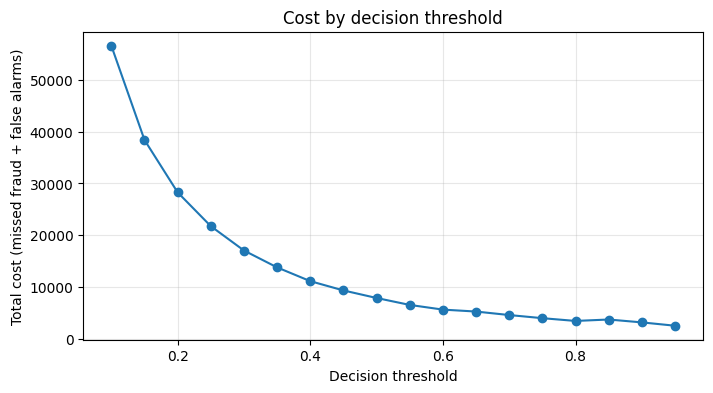

In [5]:
r = result.sort_values("threshold")
plt.figure(figsize=(8, 4))
plt.plot(r["threshold"], r["total_cost"], marker="o")
plt.xlabel("Decision threshold")
plt.ylabel("Total cost (missed fraud + false alarms)")
plt.title("Cost by decision threshold")
plt.grid(alpha=0.3)
plt.savefig("result_chart.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score

# 1) Validation set carved from TRAIN only; the test set stays untouched
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.25, stratify=y_train, random_state=42)

def make_model(weighted):
    return make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000,
                           class_weight="balanced" if weighted else None))

model = make_model(True).fit(X_fit, y_fit)
base = make_model(False).fit(X_fit, y_fit)

val_p = model.predict_proba(X_val)[:, 1]
test_p = model.predict_proba(X_test)[:, 1]
val_amt = df.loc[y_val.index, "Amount"].values
test_amt = df.loc[y_test.index, "Amount"].values
yv, yt = y_val.values, y_test.values

def cost(y, p, amt, t, fa_cost):
    pred = p >= t
    missed = amt[(y == 1) & ~pred].sum()
    false_alarms = ((y == 0) & pred).sum()
    caught = ((y == 1) & pred).sum()
    return missed + fa_cost * false_alarms, caught, false_alarms

# 2) Pick threshold on VALIDATION, report cost on TEST, for several false-alarm costs
thresholds = np.arange(0.05, 1.0, 0.01)
nothing = test_amt[yt == 1].sum()
rows = []
for fa in [1, 5, 10, 20]:
    val_costs = [cost(yv, val_p, val_amt, t, fa)[0] for t in thresholds]
    best_t = thresholds[int(np.argmin(val_costs))]
    c, caught, fas = cost(yt, test_p, test_amt, best_t, fa)
    rows.append({"false_alarm_cost": fa, "threshold_from_val": round(best_t, 2),
                 "fraud_caught": caught, "false_alarms": fas,
                 "test_cost": round(c, 1),
                 "loss_if_nothing_blocked": round(nothing, 1),
                 "reduction_%": round(100 * (1 - c / nothing), 1)})
print(pd.DataFrame(rows).to_string(index=False))

# 3) Baseline: does class weighting help?
print()
for name, m in [("Class-weighted", model), ("No class weights", base)]:
    p = m.predict_proba(X_test)[:, 1]
    print(f"{name:18s} ROC-AUC: {roc_auc_score(y_test, p):.4f}  "
          f"PR-AUC: {average_precision_score(y_test, p):.4f}")

 false_alarm_cost  threshold_from_val  fraud_caught  false_alarms  test_cost  loss_if_nothing_blocked  reduction_%
                1                0.61            88           975     2166.4                  10644.9         79.6
                5                0.99            84            66     2161.7                  10644.9         79.7
               10                0.99            84            66     2491.7                  10644.9         76.6
               20                0.99            84            66     3151.7                  10644.9         70.4

Class-weighted     ROC-AUC: 0.9720  PR-AUC: 0.7194
No class weights   ROC-AUC: 0.9527  PR-AUC: 0.7419
